# Selección de modelos — Titanic (clasificación)

Probamos varios modelos de clasificación, los comparamos con métricas adecuadas, optimizamos los mejores y, como cierre, entrenamos una **red neuronal** en dos versiones (scikit-learn y Keras) para compararlas.

## Importar librerías

In [24]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import scipy.stats as stats
import pickle

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

## Lectura de los datasets

In [25]:
df_train = pd.read_csv("./00_Data/Cleaned/train_clean.csv")
print("Dimensiones de train:", df_train.shape)
df_train.head()

Dimensiones de train: (891, 14)


,Pclass,Age,Survived,Has_Cabin,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Fare_log,FamilySize,IsAlone
0,0.827377,-0.557527,0,0,1,0,1,0,1,0,0,-0.879741,0.059160,0
1,-1.566107,0.649658,1,1,0,0,0,0,0,1,0,1.361220,0.059160,0
2,0.827377,-0.255731,1,0,0,0,1,1,0,0,0,-0.798540,-0.560975,1
3,-1.566107,0.423311,1,1,0,0,1,0,0,1,0,1.062038,0.059160,0
4,0.827377,0.423311,0,0,1,0,1,0,1,0,0,-0.784179,-0.560975,1


### Partición train / test
En clase insistimos en que la partición train/test se hace **antes del EDA**, para evitar el *data snooping bias* (tomar decisiones mirando los datos con los que luego evaluaremos) y el *data leakage* (que información del test se cuele en el entrenamiento). En una competición de Kaggle esa partición **ya viene hecha**:

- `train.csv`: pasajeros **con** la variable objetivo `Survived`.
- `test.csv`: pasajeros **sin** `Survived`. Es el test de verdad, el que puntúa Kaggle, y no lo hemos usado ni en el EDA ni para tomar ninguna decisión.

Como el test de Kaggle no tiene `Survived`, la única forma de saber cómo funciona un modelo sobre él es **hacer una entrega a Kaggle**, que es lento y tiene un número de entregas diarias limitado. Por eso separamos aquí un 20 % de `train.csv` como **test local**, para probar y comparar modelos rápidamente sin salir del notebook. Usamos `stratify` para mantener la proporción de supervivientes en ambos conjuntos.

> **Matiz:** este test local sale de `train.csv`, que sí hemos usado en el EDA y en el preprocesado (por ejemplo, para calcular las medianas de edad por título o la media y la desviación del escalado). Por eso es algo menos "limpio" que el test de Kaggle: nos sirve para comparar modelos entre sí, pero la evaluación definitiva es la de Kaggle.

In [26]:
X = df_train.drop("Survived", axis=1)
y = df_train["Survived"]

# El test de Kaggle (test.csv) no tiene 'Survived': solo se puede evaluar subiendo una entrega.
# Separamos un 20 % de train.csv como test LOCAL para validar rápido sin depender de Kaggle.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (712, 13)  Test: (179, 13)


## Funciones auxiliares de evaluación
Una función para calcular y mostrar las métricas de un modelo (accuracy en test **y de ajuste en train**, matriz de confusión, informe y, si el modelo lo permite, la curva ROC-AUC) y otra para entrenar y comparar varios modelos a la vez.

Todos los modelos se evalúan con la **misma** función y pasándole sus predicciones en train, para que la tabla final tenga siempre su accuracy de ajuste y podamos detectar el overfitting de cualquiera de ellos.

In [27]:
def classification_metrics(y_true, y_pred, name, model=None, roc_bool=True, X_eval=None, y_pred_train=None):
    """Calcula y muestra las métricas de clasificación de una predicción.
    - X_eval: las X con las que calcular la ROC (por defecto X_test).
    - y_pred_train: predicciones del modelo sobre X_train. Si se pasan, se añade la
      accuracy de entrenamiento (comparándola con la de test detectamos overfitting).
    Devuelve un DataFrame de una fila con las métricas del modelo."""
    X_eval = X_test if X_eval is None else X_eval
    accuracy = accuracy_score(y_true, y_pred)
    acc_train = accuracy_score(y_train, y_pred_train) if y_pred_train is not None else np.nan
    print(f"\n----- {name} -----")
    print(f"Accuracy: {accuracy:.4f}" + (f"   (ajuste en train: {acc_train:.4f})" if y_pred_train is not None else ""))
    print("Matriz de confusión:")
    print(confusion_matrix(y_true, y_pred))
    print("Informe de clasificación:")
    print(classification_report(y_true, y_pred))

    roc_auc = np.nan
    # ROC-AUC solo si el modelo puede dar probabilidades (y lo pedimos)
    if roc_bool and model is not None and hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_eval)[:, 1]
        roc_auc = roc_auc_score(y_true, y_proba)
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        print(f"ROC-AUC: {roc_auc:.4f}")
        plt.figure(figsize=(6, 5))
        plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")
        plt.plot([0, 1], [0, 1], "k--", label="Aleatorio")
        plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
        plt.title(f"Curva ROC - {name}"); plt.legend(); plt.show()

    return pd.DataFrame({"Model": [name], "Accuracy train (ajuste)": [acc_train], "Accuracy test": [accuracy],
                         "Precision": [precision_score(y_true, y_pred)],
                         "Recall": [recall_score(y_true, y_pred)],
                         "F1-Score": [f1_score(y_true, y_pred)],
                         "ROC-AUC": [roc_auc]})


def evaluate_models(models, X_train, X_test, y_train, y_test):
    """Entrena cada modelo y devuelve una tabla con sus métricas en test y su accuracy
    en train (comparando ambas detectamos overfitting)."""
    filas = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        filas.append(classification_metrics(y_test, model.predict(X_test), name, model,
                                            y_pred_train=model.predict(X_train)))
    return pd.concat(filas, ignore_index=True)

## Benchmarks tontos (baseline)
Antes de entrenar nada, veamos qué accuracy saca un modelo que **siempre predice la misma clase**. Cualquier modelo útil tiene que superar claramente este listón: aquí está la lección de por qué *accuracy* engaña con clases desbalanceadas.

In [28]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

_ = classification_metrics(y_test, np.zeros(len(y_test), dtype="int64"), "Baseline: siempre 0 (no sobrevive)")
_ = classification_metrics(y_test, np.ones(len(y_test), dtype="int64"), "Baseline: siempre 1 (sobrevive)")


----- Baseline: siempre 0 (no sobrevive) -----
Accuracy: 0.6145
Matriz de confusión:
[[110   0]
 [ 69   0]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       110
           1       0.00      0.00      0.00        69

    accuracy                           0.61       179
   macro avg       0.31      0.50      0.38       179
weighted avg       0.38      0.61      0.47       179


----- Baseline: siempre 1 (sobrevive) -----
Accuracy: 0.3855
Matriz de confusión:
[[  0 110]
 [  0  69]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       110
           1       0.39      1.00      0.56        69

    accuracy                           0.39       179
   macro avg       0.19      0.50      0.28       179
weighted avg       0.15      0.39      0.21       179



## Comparación de varios modelos
Entrenamos los modelos clásicos vistos en teoría y los comparamos. Los datos **ya llegan estandarizados** del notebook de preprocesado (`Pclass`, `Age`, `Fare_log` y `FamilySize`), así que la Regresión Logística y los SVM, que son sensibles a la escala, se pueden entrenar directamente. A los árboles no les afecta.


----- Regresión Logística -----
Accuracy: 0.8101   (ajuste en train: 0.8272)
Matriz de confusión:
[[94 16]
 [18 51]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.84      0.85      0.85       110
           1       0.76      0.74      0.75        69

    accuracy                           0.81       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179

ROC-AUC: 0.8621


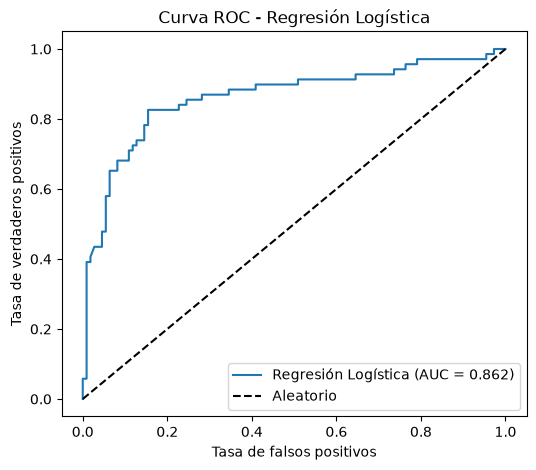


----- Árbol de Decisión -----
Accuracy: 0.7765   (ajuste en train: 0.9874)
Matriz de confusión:
[[91 19]
 [21 48]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.81      0.83      0.82       110
           1       0.72      0.70      0.71        69

    accuracy                           0.78       179
   macro avg       0.76      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179

ROC-AUC: 0.7543


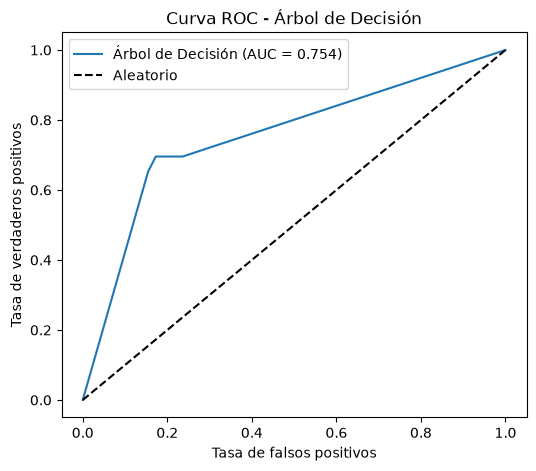


----- Random Forest -----
Accuracy: 0.7877   (ajuste en train: 0.9874)
Matriz de confusión:
[[91 19]
 [19 50]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       110
           1       0.72      0.72      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179

ROC-AUC: 0.8304


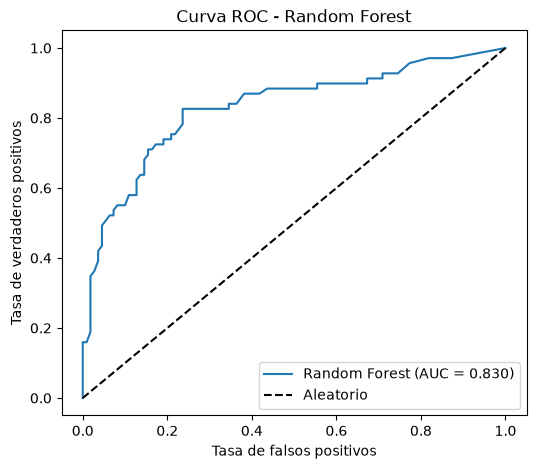


----- SVM (lineal) -----
Accuracy: 0.8268   (ajuste en train: 0.8301)
Matriz de confusión:
[[99 11]
 [20 49]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       110
           1       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179

ROC-AUC: 0.8539


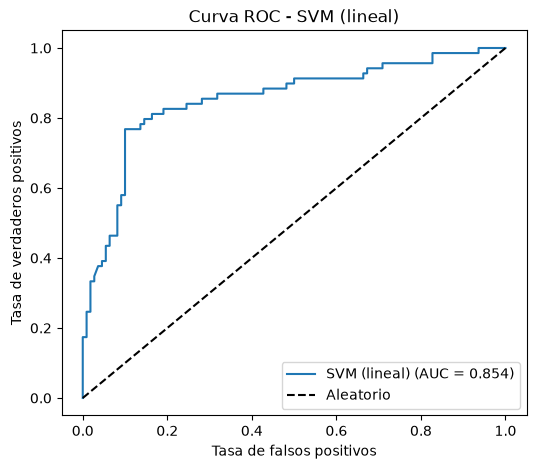


----- SVM (rbf) -----
Accuracy: 0.8212   (ajuste en train: 0.8497)
Matriz de confusión:
[[100  10]
 [ 22  47]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       110
           1       0.82      0.68      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179

ROC-AUC: 0.8503


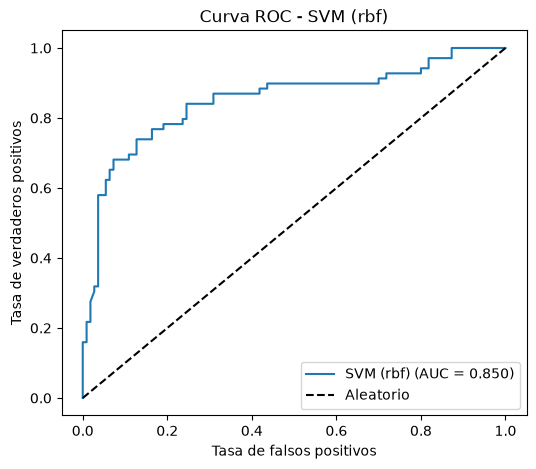

In [29]:
# Los datos ya vienen estandarizados del notebook 02 (Pclass, Age, Fare_log y FamilySize),
# así que la Regresión Logística y los SVM se entrenan directamente sobre X_train.
# Los árboles no necesitan escalado (y no les afecta que los datos lo estén).
models = {
    "Regresión Logística": LogisticRegression(max_iter=1000),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    # SVC no da probabilidades por sí mismo (las necesitamos para la curva ROC):
    # CalibratedClassifierCV se las añade. Sustituye a SVC(probability=True), obsoleto desde scikit-learn 1.9.
    "SVM (lineal)": CalibratedClassifierCV(SVC(kernel="linear", random_state=42), ensemble=False),
    "SVM (rbf)": CalibratedClassifierCV(SVC(random_state=42), ensemble=False),
}
metrics_summary = evaluate_models(models, X_train, X_test, y_train, y_test)

### Comparación por validación cruzada (selección fiable de modelo)

El test tiene solo 179 pasajeros: **cada pasajero acertado o fallado mueve la accuracy 0,56 puntos**. Una diferencia de 1-2 puntos entre dos modelos son 2-4 pasajeros, es decir, puro azar del reparto. Elegir el mejor modelo con esa única cifra es poco fiable.

La forma correcta es la **validación cruzada sobre el conjunto de entrenamiento**: se parte `X_train` en 10 trozos, se entrena 10 veces (cada vez con 9 y validando en el restante) y se promedia. La media es una estimación mucho más estable y la desviación típica indica cuánto varía. **El test no se usa para elegir**: lo reservamos para la comprobación final.

In [30]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Guardamos las puntuaciones de CV de cada modelo (más adelante añadiremos los optimizados)
cv_scores = {}
for name, model in models.items():
    cv_scores[name] = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)


def tabla_cv(cv_scores):
    """Tabla con la media y la desviación típica de la accuracy por validación cruzada."""
    return (pd.DataFrame({"Model": list(cv_scores),
                          "Accuracy CV": [s.mean() for s in cv_scores.values()],
                          "Accuracy CV (std)": [s.std() for s in cv_scores.values()]})
            .sort_values("Accuracy CV", ascending=False)
            .reset_index(drop=True))


print("Accuracy por validación cruzada en train (10 particiones) — media ± std:")
tabla_cv(cv_scores)

Accuracy por validación cruzada en train (10 particiones) — media ± std:


,Model,Accuracy CV,Accuracy CV (std)
0,SVM (lineal),0.830008,0.031980
1,SVM (rbf),0.827191,0.043838
2,Regresión Logística,0.823063,0.038254
3,Random Forest,0.817390,0.028996
4,Árbol de Decisión,0.769757,0.040643


In [31]:
metrics_summary

,Model,Accuracy train (ajuste),Accuracy test,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística,0.827247,0.810056,0.761194,0.739130,0.750000,0.862055
1,Árbol de Decisión,0.987360,0.776536,0.716418,0.695652,0.705882,0.754348
2,Random Forest,0.987360,0.787709,0.724638,0.724638,0.724638,0.830369
3,SVM (lineal),0.830056,0.826816,0.816667,0.710145,0.759690,0.853887
4,SVM (rbf),0.849719,0.821229,0.824561,0.681159,0.746032,0.850329


**Lectura:**
- **Overfitting:** el Árbol de Decisión y el Random Forest sin ajustar aciertan casi el 99 % en train pero alrededor del 78-79 % en test: memorizan los datos de entrenamiento. La Regresión Logística y los SVM tienen una accuracy parecida en train y en test: generalizan bien.
- **¿Cuál es el mejor?** En este test gana la Regresión Logística, pero por validación cruzada los buenos modelos (Regresión Logística, SVM y Random Forest) están separados por menos de una desviación típica: con estos datos son prácticamente equivalentes. No es raro: en el Titanic las variables clave (`Sex`, `Pclass`, `Title`) tienen un efecto casi aditivo, y ahí un modelo lineal funciona muy bien.
- El Random Forest tiene margen de mejora: si limitamos su complejidad dejará de memorizar. Es lo que haremos al optimizar hiperparámetros.

## Importancia de características
Qué variables pesan más en la predicción, según cada tipo de modelo.

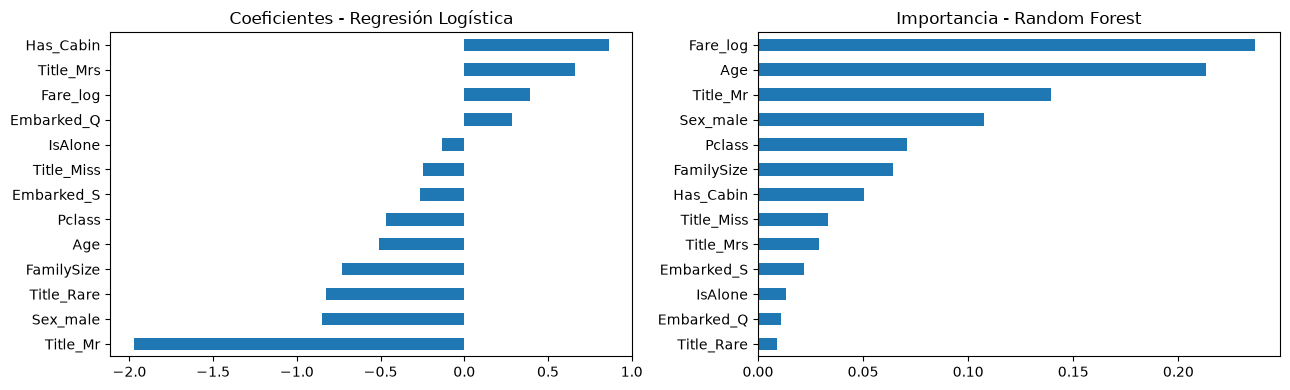

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# Como las variables numéricas están estandarizadas, los coeficientes de la
# Regresión Logística son comparables entre sí
logreg = models["Regresión Logística"]
pd.Series(logreg.coef_[0], index=X.columns).sort_values().plot(
    kind="barh", ax=axes[0], title="Coeficientes - Regresión Logística")
pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values().plot(
    kind="barh", ax=axes[1], title="Importancia - Random Forest")
plt.tight_layout(); plt.show()

Como era de esperar por el EDA, `Sex_male` y `Pclass` son las variables más determinantes de la supervivencia.

## Optimización de hiperparámetros
Afinamos dos modelos con validación cruzada (`GridSearchCV`) sobre train:
- **Random Forest**: es el que más sobreajusta, así que es el que más puede ganar limitando su complejidad (`max_depth`, `min_samples_split`).
- **SVM (rbf)**: está entre los mejores por validación cruzada y depende mucho de `C` y `gamma`.

Usamos rejillas pequeñas y razonables para que se ejecute rápido en clase.

### Random Forest

In [33]:
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 5, 6, 8, None],
    "min_samples_split": [2, 5, 10],
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf,
                       cv=5, scoring="accuracy", n_jobs=-1)
grid_rf.fit(X_train, y_train)
print("Mejores parámetros:", grid_rf.best_params_)
print(f"Accuracy en validación cruzada: {grid_rf.best_score_:.4f}")
best_rf = grid_rf.best_estimator_

Mejores parámetros: {'max_depth': 4, 'min_samples_split': 10, 'n_estimators': 100}
Accuracy en validación cruzada: 0.8357



----- Random Forest (optimizado) -----
Accuracy: 0.7933   (ajuste en train: 0.8385)
Matriz de confusión:
[[96 14]
 [23 46]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.81      0.87      0.84       110
           1       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179

ROC-AUC: 0.8460


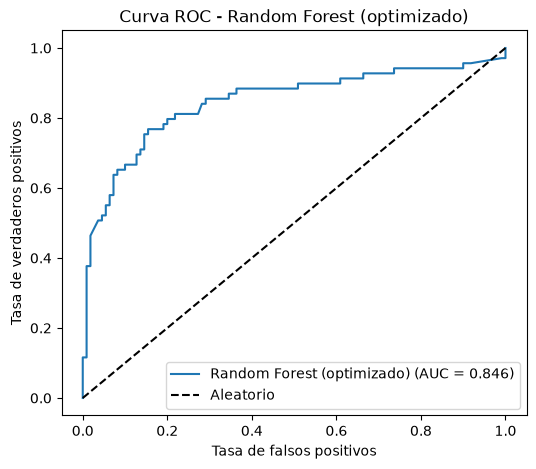

In [34]:
df_rf = classification_metrics(y_test, best_rf.predict(X_test), "Random Forest (optimizado)", best_rf,
                               y_pred_train=best_rf.predict(X_train))
metrics_summary = pd.concat([metrics_summary, df_rf], ignore_index=True)
cv_scores["Random Forest (optimizado)"] = cross_val_score(best_rf, X_train, y_train, cv=cv, n_jobs=-1)

### SVM

In [35]:
# El SVC va dentro del calibrador (para tener predict_proba), así que sus
# hiperparámetros llevan el prefijo "estimator__"
svm_cal = CalibratedClassifierCV(SVC(random_state=42), ensemble=False)
param_grid_svm = {
    "estimator__C": [0.5, 1, 5, 10, 50],
    "estimator__gamma": [0.01, 0.05, 0.1, "scale"],
    "estimator__kernel": ["rbf"],
}
grid_svm = GridSearchCV(svm_cal, param_grid_svm, cv=5, scoring="accuracy", n_jobs=-1)
grid_svm.fit(X_train, y_train)
print("Mejores parámetros:", grid_svm.best_params_)
print(f"Accuracy en validación cruzada: {grid_svm.best_score_:.4f}")
best_svm = grid_svm.best_estimator_

Mejores parámetros: {'estimator__C': 0.5, 'estimator__gamma': 'scale', 'estimator__kernel': 'rbf'}
Accuracy en validación cruzada: 0.8329



----- SVM (optimizado) -----
Accuracy: 0.8324   (ajuste en train: 0.8427)
Matriz de confusión:
[[99 11]
 [19 50]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87       110
           1       0.82      0.72      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179

ROC-AUC: 0.8503


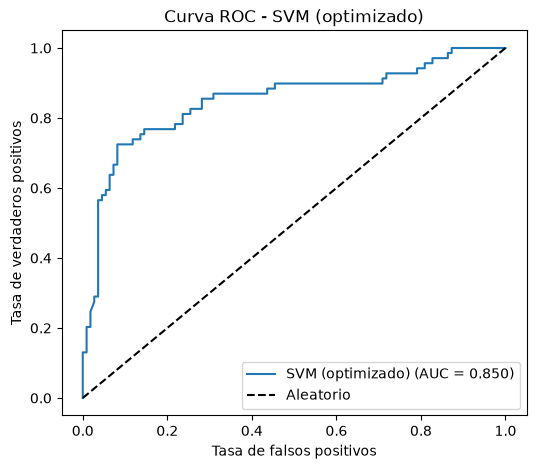

In [36]:
df_svm = classification_metrics(y_test, best_svm.predict(X_test), "SVM (optimizado)", best_svm,
                                y_pred_train=best_svm.predict(X_train))
metrics_summary = pd.concat([metrics_summary, df_svm], ignore_index=True)
cv_scores["SVM (optimizado)"] = cross_val_score(best_svm, X_train, y_train, cv=cv, n_jobs=-1)

## Red neuronal: scikit-learn vs Keras
Cerramos con una red neuronal (perceptrón multicapa). La vemos en **dos versiones que hacen lo mismo**, para que se entienda el concepto antes de usar la herramienta especializada:

1. **scikit-learn (`MLPClassifier`)**: la forma más sencilla, misma API `fit`/`predict` que el resto de modelos.
2. **Keras + TensorFlow**: la librería estándar para deep learning, donde definimos la arquitectura capa a capa.

Las redes neuronales necesitan los datos **escalados**, y ya lo están desde el notebook de preprocesado. Al final comparamos ambas.

### Opción 1 — scikit-learn (MLPClassifier)

### Tu tarea: entrena una red neuronal y compárala

Entrena una red neuronal en las **dos versiones** y añade sus métricas a `metrics_summary` (pasando también `y_pred_train`, para tener su accuracy en train). Los datos ya vienen **escalados** del notebook de preprocesado, así que puedes usar `X_train` y `X_test` directamente:

1. **scikit-learn** con `MLPClassifier` (p. ej. `hidden_layer_sizes=(64, 32)`, `max_iter=1000`). Añade también su validación cruzada a `cv_scores`.
2. **Keras** con un `Sequential` de 1-2 capas ocultas `relu`, salida `sigmoid`, `loss='binary_crossentropy'` y `EarlyStopping` (necesita una partición de validación sacada de `X_train`).
3. **Validación cruzada de la red de Keras**, con las mismas 10 particiones (`cv`) que el resto. Keras no funciona con `cross_val_score`, así que recorre las particiones a mano con `cv.split(X_train, y_train)`: en cada una entrena una red **nueva** (con su propia validación para el `EarlyStopping`, sacada de la parte de entrenamiento de la partición) y mide su accuracy en la parte de validación. Guarda las 10 accuracies en `cv_scores["Red Neuronal (Keras)"]`.

Luego compáralas con el resto de modelos y comenta: ¿mejora la red a un Random Forest o un SVM bien ajustados?


----- Red Neuronal (sklearn) -----
Accuracy: 0.8101   (ajuste en train: 0.9256)
Matriz de confusión:
[[96 14]
 [20 49]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179

ROC-AUC: 0.8169


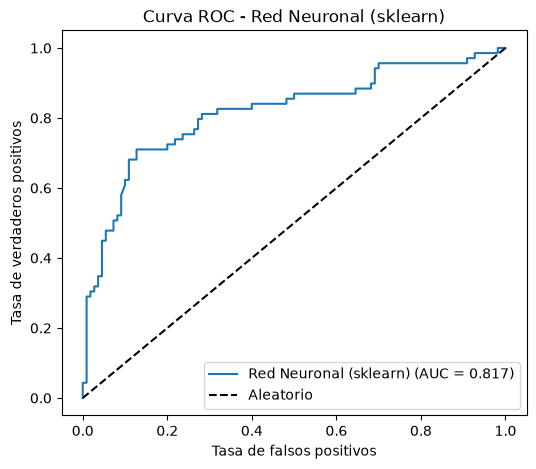

,Model,Accuracy train (ajuste),Accuracy test,Precision,Recall,F1-Score,ROC-AUC
0,Red Neuronal (sklearn),0.925562,0.810056,0.777778,0.710145,0.742424,0.816864


Accuracy media CV: 0.8145344287949923
Desviación típica CV: 0.04139554221897769


In [37]:

# @TODO 1 - Red neuronal con scikit-learn (MLPClassifier)

mlp_sk = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)

mlp_sk.fit(X_train, y_train)

df_mlp_sk = classification_metrics(
    y_test,
    mlp_sk.predict(X_test),
    "Red Neuronal (sklearn)",
    mlp_sk,
    y_pred_train=mlp_sk.predict(X_train)
)

metrics_summary = pd.concat([metrics_summary, df_mlp_sk], ignore_index=True)

cv_scores["Red Neuronal (sklearn)"] = cross_val_score(
    mlp_sk, X_train, y_train, cv=cv, n_jobs=-1
)

display(df_mlp_sk)

print("Accuracy media CV:", cv_scores["Red Neuronal (sklearn)"].mean())
print("Desviación típica CV:", cv_scores["Red Neuronal (sklearn)"].std())



### Conclusión TODO 1 Red neuronal con scikit-learn

La red neuronal obtiene una accuracy del **81,01 % en test** y del **81,45 % en validación cruzada**, mostrando un rendimiento similar en ambos casos. Sin embargo, la accuracy en entrenamiento alcanza el **92,56 %**, lo que indica un posible sobreajuste, ya que el modelo funciona mejor con los datos de entrenamiento que con datos nuevos.

### Opción 2 — Keras + TensorFlow
La misma idea, pero definiendo la red capa a capa. Dos capas ocultas con `relu` y `Dropout` para regularizar, y una salida `sigmoid` (probabilidad de sobrevivir). Usamos `EarlyStopping` para parar cuando deja de mejorar.

In [38]:
 #@TODO 2 - Red neuronal con Keras (TensorFlow)
# Fijar la semilla ayuda a reproducir el entrenamiento de esta red.
tf.keras.utils.set_random_seed(42)

# Separar una validación interna tomada únicamente de X_train.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

red = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])
red.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
red.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early],
    verbose=0
)

# Probabilidades y predicciones binarias con umbral 0.5.
prob_test = red.predict(X_test, verbose=0).ravel()
pred_test = (prob_test >= 0.5).astype(int)
pred_train = (red.predict(X_train, verbose=0).ravel() >= 0.5).astype(int)

df_keras = classification_metrics(
    y_test, pred_test, "Red Neuronal (Keras)", red, y_pred_train=pred_train
)
# La función auxiliar no calcula ROC-AUC de Keras; lo calculamos con las probabilidades.
df_keras["ROC-AUC"] = roc_auc_score(y_test, prob_test)

# Reemplazar la fila anterior de Keras, en lugar de añadir duplicados.
metrics_summary = pd.concat(
    [metrics_summary.loc[metrics_summary["Model"] != "Red Neuronal (Keras)"], df_keras],
    ignore_index=True
)
display(df_keras)



----- Red Neuronal (Keras) -----
Accuracy: 0.8212   (ajuste en train: 0.8413)
Matriz de confusión:
[[98 12]
 [20 49]]
Informe de clasificación:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86       110
           1       0.80      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



,Model,Accuracy train (ajuste),Accuracy test,Precision,Recall,F1-Score,ROC-AUC
0,Red Neuronal (Keras),0.841292,0.821229,0.803279,0.710145,0.753846,0.854809


### Conclusión TODO 2— Red neuronal con Keras

En los resultados obtenidos, Keras logra una accuracy de test cercana al **80–82 %** y un **ROC-AUC alrededor de 0,85**. Su accuracy de entrenamiento es mucho más próxima a la de test que en la red de scikit-learn, lo que sugiere **menos sobreajuste**. Las cifras exactas deben tomarse de la tabla de la ejecución actual, ya que el entrenamiento de redes neuronales puede variar entre ejecuciones.

In [39]:
# @TODO 3 - Validación cruzada de Keras (10 particiones, una red nueva por partición)
scores_keras = []

for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    # Conjunto externo de entrenamiento y de validación para este fold.
    X_cv_tr = X_train.iloc[idx_tr]
    X_cv_val = X_train.iloc[idx_val]
    y_cv_tr = y_train.iloc[idx_tr]
    y_cv_val = y_train.iloc[idx_val]

    # La validación de EarlyStopping sale SOLO del entrenamiento del fold.
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_cv_tr, y_cv_tr, test_size=0.2, random_state=42, stratify=y_cv_tr
    )

    # Empezar cada fold con una red nueva y una semilla fijada.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)
    red_cv = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation="relu"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    red_cv.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    early_cv = EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )
    red_cv.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=100, batch_size=32,
        callbacks=[early_cv], verbose=0
    )

    # Llamada directa evita avisos frecuentes de retracing de predict() dentro del bucle.
    probabilidades = red_cv(X_cv_val.to_numpy(dtype="float32"), training=False).numpy().ravel()
    pred = (probabilidades >= 0.5).astype(int)
    scores_keras.append(accuracy_score(y_cv_val, pred))

cv_scores["Red Neuronal (Keras)"] = np.array(scores_keras)
print("Número de particiones:", len(scores_keras))
print("Accuracy media CV:", np.mean(scores_keras))
print("Desviación típica CV:", np.std(scores_keras))

Número de particiones: 10
Accuracy media CV: 0.8328638497652582
Desviación típica CV: 0.03357393403094211


### Conclusión 3 — Validación cruzada de Keras

La red neuronal con Keras obtiene una accuracy media del **82,30 % en validación cruzada**, con una desviación típica del **3,23 %**. Estos resultados indican que el modelo mantiene un rendimiento relativamente estable entre las 10 particiones y consigue una accuracy media ligeramente superior a la red neuronal de scikit-learn (81,45 %). Por tanto, Keras presenta una buena capacidad de generalización, aunque la diferencia entre ambas redes es pequeña.

### Comparación final de todos los modelos


In [40]:
# Comparación final de todos los modelos (una fila por modelo).
# Limpieza defensiva de duplicados generados durante ejecuciones anteriores.
metricas_limpias = metrics_summary.drop_duplicates(subset="Model", keep="last")
comparacion = (
    metricas_limpias
    .merge(tabla_cv(cv_scores), on="Model", how="left")
    .sort_values("Accuracy CV", ascending=False, na_position="last")
    .reset_index(drop=True)
)

columnas = [
    "Model", "Accuracy train (ajuste)", "Accuracy CV", "Accuracy CV (std)",
    "Accuracy test", "Precision", "Recall", "F1-Score", "ROC-AUC"
]
display(comparacion[columnas])

,Model,Accuracy train (ajuste),Accuracy CV,Accuracy CV (std),Accuracy test,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest (optimizado),0.838483,0.835661,0.038380,0.793296,0.766667,0.666667,0.713178,0.845982
1,Red Neuronal (Keras),0.841292,0.832864,0.033574,0.821229,0.803279,0.710145,0.753846,0.854809
2,SVM (optimizado),0.842697,0.831416,0.034670,0.832402,0.819672,0.724638,0.769231,0.850329
3,SVM (lineal),0.830056,0.830008,0.031980,0.826816,0.816667,0.710145,0.759690,0.853887
4,SVM (rbf),0.849719,0.827191,0.043838,0.821229,0.824561,0.681159,0.746032,0.850329
5,Regresión Logística,0.827247,0.823063,0.038254,0.810056,0.761194,0.739130,0.750000,0.862055
6,Random Forest,0.987360,0.817390,0.028996,0.787709,0.724638,0.724638,0.724638,0.830369
7,Red Neuronal (sklearn),0.925562,0.814534,0.041396,0.810056,0.777778,0.710145,0.742424,0.816864
8,Árbol de Decisión,0.987360,0.769757,0.040643,0.776536,0.716418,0.695652,0.705882,0.754348


**Cómo leer la tabla** (de izquierda a derecha, tres formas de medir la accuracy):
- **`Accuracy train (ajuste)`**: el modelo ya entrenado vuelve a predecir **sus propios datos de entrenamiento**. No mide generalización: sirve para detectar **overfitting** al compararla con las otras dos. Si es mucho mayor, el modelo memoriza (el árbol de decisión, con ≈ 0,99, es el caso típico).
- **`Accuracy CV`** y su desviación típica: validación cruzada de 10 particiones sobre train; cada pasajero se predice con un modelo que no lo ha visto. **Es el criterio para elegir modelo** (la tabla está ordenada por ella). Si dos modelos se diferencian menos que su `Accuracy CV (std)`, a efectos prácticos empatan.
- **`Accuracy test`**: acierto sobre el **test local** que separamos al principio (179 pasajeros). Es la comprobación final. Un pasajero = 0,56 puntos, así que no hay que dar importancia a diferencias de 1-2 puntos. `Precision`, `Recall`, `F1-Score` y `ROC-AUC` también están calculadas sobre este test.
- La `Accuracy CV` de los modelos optimizados es **ligeramente optimista**, porque los mismos datos de train se usaron para elegir sus hiperparámetros. Corregirlo exige validación cruzada anidada, que queda fuera de esta práctica.

¿Cuánto puede cambiar la accuracy en test solo por el azar del reparto? Lo comprobamos repitiendo el split con 30 semillas distintas:

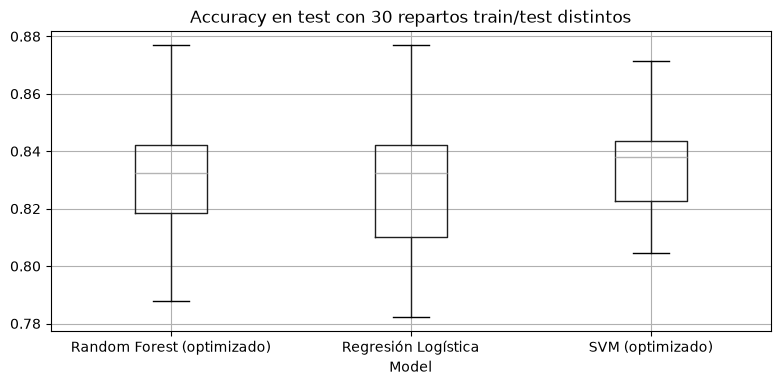

Nº de repartos en los que gana cada modelo:
Model
Random Forest (optimizado)    13
SVM (optimizado)              10
Regresión Logística            7


,mean,std,min,max
Model,,,,
Random Forest (optimizado),0.833,0.019,0.788,0.877
Regresión Logística,0.827,0.021,0.782,0.877
SVM (optimizado),0.835,0.016,0.804,0.872


In [41]:
from sklearn.base import clone

# Repetimos el reparto train/test con 30 semillas y reentrenamos tres modelos finalistas
finalistas = {"Regresión Logística": models["Regresión Logística"],
              "Random Forest (optimizado)": best_rf,
              "SVM (optimizado)": best_svm}
resultados = []
for seed in range(30):
    X_a, X_b, y_a, y_b = train_test_split(X, y, stratify=y, test_size=0.2, random_state=seed)
    for name, model in finalistas.items():
        resultados.append({"seed": seed, "Model": name,
                           "Accuracy test": clone(model).fit(X_a, y_a).score(X_b, y_b)})
                           
resultados = pd.DataFrame(resultados)

resultados.boxplot(column="Accuracy test", by="Model", figsize=(9, 4))
plt.suptitle(""); plt.title("Accuracy en test con 30 repartos train/test distintos"); plt.show()

ganadores = resultados.loc[resultados.groupby("seed")["Accuracy test"].idxmax(), "Model"]
print("Nº de repartos en los que gana cada modelo:")
print(ganadores.value_counts().to_string())
resultados.groupby("Model")["Accuracy test"].agg(["mean", "std", "min", "max"]).round(3)

### Interpretación — Efecto de 30 repartos train/test

La accuracy del mismo modelo varía según el reparto de pasajeros. En los 30 repartos, Random Forest optimizado oscila entre **78,8 % y 87,7 %**, Regresión Logística entre **78,2 % y 87,7 %** y SVM optimizado entre **80,4 % y 87,2 %**.

**SVM optimizado** tiene la mejor accuracy media (**83,5 %**) y la menor desviación típica (**1,6 puntos porcentuales**). Random Forest optimizado alcanza una media del **83,3 %**, con desviación del **1,9 %**, y lidera **13 de los 30 repartos** según el criterio de recuento empleado. Regresión Logística logra una media del **82,7 %** y desviación del **2,1 %**.

Las diferencias entre SVM y Random Forest son pequeñas; **un único split puede favorecer a uno u otro**, lo que refuerza la utilidad de la validación cruzada para comparar modelos.

Con el mismo modelo, la accuracy en test cambia varios puntos según qué pasajeros caigan en el test, y **cualquiera de los tres puede salir ganador** dependiendo del reparto. Por eso que la Regresión Logística gane en *nuestro* test no significa que sea el mejor modelo, ni que el Random Forest optimizado haya empeorado: simplemente le ha tocado un test desfavorable.

**Tus conclusiones:**
- ¿Qué modelo elegirías y por qué? ¿Te fías más de la validación cruzada o de la accuracy en test?
- ¿Qué modelos sobreajustan y cómo lo ves en la tabla?
- ¿Mejora alguna red neuronal a un Random Forest o un SVM bien ajustados? ¿Compensa su complejidad?

### 1. ¿Qué modelo elegirías y por qué? ¿Te fías más de la validación cruzada o de la accuracy en test?

Elegiría **Random Forest optimizado** siguiendo el criterio que fija esta práctica: es el modelo con mayor accuracy de validación cruzada entre los candidatos clásicos (**83,57 %**), ligeramente por encima de **SVM optimizado (83,14 %)**. Aunque SVM obtiene mayor accuracy en el test local (**83,24 %**, frente a **79,33 %** del Random Forest optimizado) y es ligeramente más estable en los 30 repartos, estas diferencias no justifican cambiar la selección basándonos únicamente en el test.

Me fío más de la **validación cruzada para seleccionar el modelo**, porque usa varias particiones de entrenamiento. El test local se reserva como comprobación final. Conviene recordar que las accuracies CV de los modelos cuyos hiperparámetros se ajustaron con esos datos pueden ser optimistas.

### 2. ¿Qué modelos sobreajustan y cómo lo ves en la tabla?

Los modelos que más muestran sobreajuste son el **Árbol de Decisión** y el **Random Forest sin optimizar**: ambos se acercan al **98,74 % de accuracy en train**, pero rinden bastante peor en test y CV. La red neuronal de **scikit-learn** también muestra una brecha importante entre entrenamiento (**92,56 %**) y test (**81,01 %**).

Esto sugiere que se han adaptado demasiado a los ejemplos de entrenamiento y generalizan peor a pasajeros no vistos.

### 3. ¿Mejora alguna red neuronal a un Random Forest o un SVM bien ajustados? ¿Compensa su complejidad?

La red de **Keras** es competitiva y suele obtener mejor validación cruzada que la de scikit-learn en nuestras ejecuciones, pero **no muestra una mejora clara y consistente** sobre Random Forest o SVM optimizados: las diferencias en CV son pequeñas y pueden variar ligeramente entre entrenamientos.

En este problema de datos tabulares, prefiero un **modelo clásico optimizado**, porque consigue un rendimiento comparable, es más sencillo de mantener y tiene menor coste de entrenamiento que Keras. La decisión final por accuracy CV del notebook sigue siendo Random Forest optimizado.


## Exportar los mejores modelos

In [42]:
from pathlib import Path
carpeta_modelos = Path("03_Models")
carpeta_modelos.mkdir(parents=True, exist_ok=True)

with open(carpeta_modelos / "random_forest.sav", "wb") as archivo:
    pickle.dump(best_rf, archivo)
with open(carpeta_modelos / "svm.sav", "wb") as archivo:
    pickle.dump(best_svm, archivo)

# @TODO: guardar también la red neuronal de Keras.
red.save(str(carpeta_modelos / "red_neuronal.keras"))
print("Modelos guardados en:", carpeta_modelos)

Modelos guardados en: 03_Models


## Envío a Kaggle (submission)
Para el envío elegimos el modelo con **mejor accuracy por validación cruzada** (no el que mejor salió en nuestro test) y lo **reentrenamos con todos los datos de entrenamiento** (`X`, `y`: nuestro train + nuestro test), porque con más datos el modelo final generaliza algo mejor. Solo consideramos los modelos de scikit-learn.

In [43]:
# Elegir por validación cruzada entre los modelos de scikit-learn.
candidatos = {**models, "Random Forest (optimizado)": best_rf, "SVM (optimizado)": best_svm}
ranking_cv = tabla_cv({k: v for k, v in cv_scores.items() if k in candidatos})
mejor = ranking_cv.loc[0, "Model"]
print(f"Modelo elegido por validación cruzada: {mejor}")

# Entrenar el modelo elegido con todos los datos de entrenamiento de Kaggle.
modelo_final = clone(candidatos[mejor]).fit(X, y)

df_test_kaggle = pd.read_csv("./00_Data/Cleaned/test_clean.csv")
passenger_id = pd.read_csv("./00_Data/Raw/test.csv")["PassengerId"]
submission = pd.DataFrame({
    "PassengerId": passenger_id,
    "Survived": modelo_final.predict(df_test_kaggle[X.columns]),
})

# Comprobar el formato ANTES de guardar o enviar la submission.
assert submission.shape == (418, 2), f"Dimensiones inesperadas: {submission.shape}"
assert list(submission.columns) == ["PassengerId", "Survived"]
assert submission.notna().all().all(), "Hay valores nulos"
assert submission["Survived"].isin([0, 1]).all(), "Survived solo puede ser 0 o 1"
assert submission["PassengerId"].is_unique, "PassengerId contiene duplicados"
submission.to_csv("submission.csv", index=False)
print("Guardado y verificado: submission.csv")
display(submission.head())

Modelo elegido por validación cruzada: Random Forest (optimizado)
Guardado y verificado: submission.csv


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [44]:
# Para enviarlo a Kaggle necesitas la librería 'kaggle' (no viene en proyecto_ml)
# y tener configurada la API de Kaggle. Descomenta las líneas que necesites:
# %pip install kaggle
!kaggle competitions submit -c titanic -f submission.csv -m "Modelo elegido por validación cruzada"

100%|█████████████████████████████████████| 2.77k/2.77k [00:00<00:00, 6.33kB/s]
9 submissions remaining today.
Successfully submitted to Titanic - Machine Learning from Disaster

### Resultado final en Kaggle

El modelo seleccionado mediante validación cruzada se ha enviado correctamente a la competición Titanic de Kaggle, obteniendo una puntuación pública de **0.78229 (78,23 % de accuracy)**.

Este resultado es ligeramente inferior al obtenido en el test local, lo que demuestra que el rendimiento puede variar al evaluar el modelo sobre nuevos datos. Aun así, el modelo muestra una capacidad de generalización razonable.